In [1]:
# Import the foundational library for data manipulation and analysis
import pandas as pd

# Import the core library for numerical operations
import numpy as np

# Import the primary plotting library
import matplotlib.pyplot as plt

# Import a higher-level plotting library built on top of Matplotlib
import seaborn as sns
# This is a 'magic command' in Jupyter. It ensures that any plots
# generated by Matplotlib or Seaborn will be displayed directly inside the notebook.
%matplotlib inline

# Import the specific function from scikit-learn to fetch our dataset
from sklearn.datasets import fetch_california_housing

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
housing_bunch = fetch_california_housing()

print("keys available in the Bunch object:")
print(housing_bunch.keys())

keys available in the Bunch object:
dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])


In [4]:
print(housing_bunch.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [5]:
# Create a pandas DataFrame from the feature data and feature names.
# The pd.DataFrame() constructor is a powerful and flexible function.
# - The first argument is the data itself, which in our case is the NumPy array `housing_bunch.data`.
# - The `columns` argument takes a list of strings to use as the column headers.
housing_df = pd.DataFrame(data=housing_bunch.data, columns=housing_bunch.feature_names)

# Now, let's add the target variable (median house value) to our DataFrame.
# The target data is stored in `housing_bunch.target`.
# We can create a new column in a DataFrame by assigning a Series or array-like object to it
# using dictionary-style key assignment. We will name this new column 'MedHouseVal'.
# The name 'MedHouseVal' is derived from the dataset's description, representing Median House Value.
housing_df['MedHouseVal'] = housing_bunch.target

# Let's print a confirmation message.
print("DataFrame created successfully!")
print(f"The DataFrame has {housing_df.shape[0]} rows and {housing_df.shape[1]} columns.")

DataFrame created successfully!
The DataFrame has 20640 rows and 9 columns.


In [6]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [7]:
housing_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [9]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [10]:
housing_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

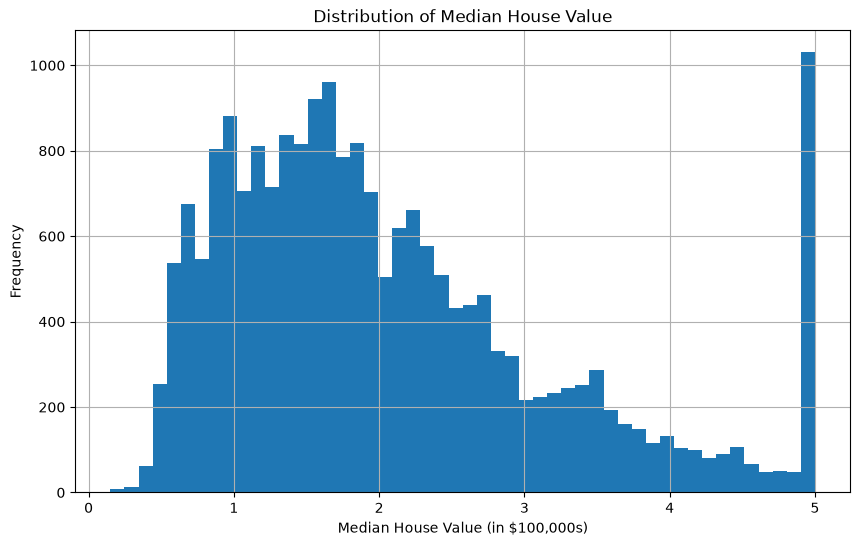

In [11]:
housing_df['MedHouseVal'].hist(bins=50, figsize=(10, 6))
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value (in $100,000s)')
plt.ylabel('Frequency')
plt.show()

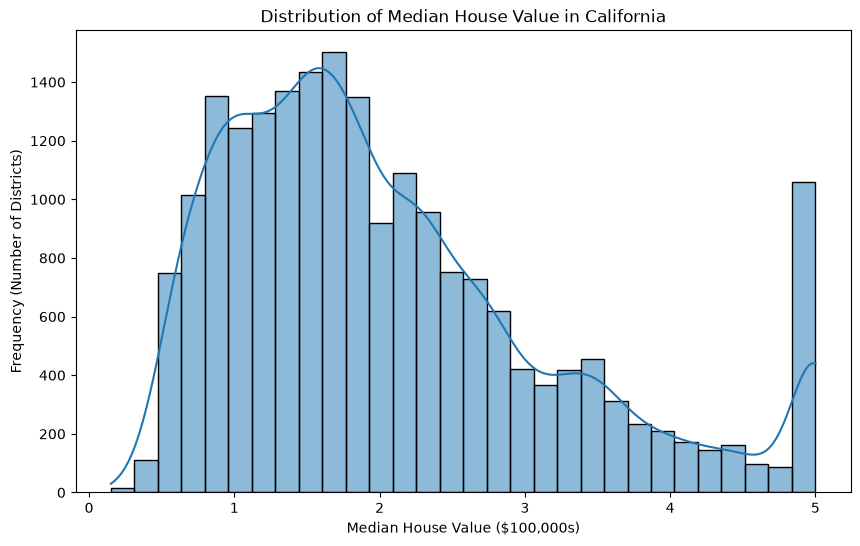

In [12]:
# We'll use both seaborn and matplotlib for plotting
import seaborn as sns
import matplotlib.pyplot as plt

# It's good practice to set the figure size for better readability
plt.figure(figsize=(10, 6))

# Create the histogram using seaborn's histplot function.
# - data: The DataFrame containing our data.
# - x: The name of the column we want to plot.
# - bins: The number of bars to divide the data into. A good starting point.
# - kde: Kernel Density Estimate. This adds a smoothed line over the histogram
#        to better visualize the shape of the distribution.
sns.histplot(data=housing_df, x='MedHouseVal', bins=30, kde=True)

# Add a title and labels to make the plot informative
plt.title('Distribution of Median House Value in California')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Frequency (Number of Districts)')

# Display the plot
plt.show()